In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
df=pd.read_csv(r"/crop_recoomendation_dataset.zip")



In [ ]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [ ]:
# Standardize column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
df = df.drop_duplicates()

# Convert standard numeric columns
numeric_cols = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values
df = df.dropna()

# Check dataset
print(df.info())
print(df.describe())
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

# Save cleaned dataset
df.to_csv("cleaned_crop_dataset.csv", index=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB
None
                 N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931     5.063749    22.263812   
min       0.000000     5.000000     5.000000     8.825675    14.258040   
25%      21.000000    28.000000    

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# X contains the input features used to predict the crop
X = df.drop("label", axis=1)

# y contains the target crop name
y = df["label"]

# Display the input and target shapes
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Display the input feature names
print("Input features:", X.columns.tolist())

# Display the unique crop names
print("Crop classes:", sorted(y.unique()))

# Count the number of different crops
print("Number of crop classes:", y.nunique())

Input features shape: (2200, 7)
Target shape: (2200,)
Input features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Crop classes: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']
Number of crop classes: 22


In [ ]:
# Import LabelEncoder
from sklearn.preprocessing import LabelEncoder

# Create the label encoder
le = LabelEncoder()

# Convert crop names into integer labels
y_encoded = le.fit_transform(y)

# Display the mapping between crop names and encoded numbers
for number, crop in enumerate(le.classes_):
    print(number, ":", crop)

# Check the encoded target
print("Encoded target:", y_encoded[:10])

0 : apple
1 : banana
2 : blackgram
3 : chickpea
4 : coconut
5 : coffee
6 : cotton
7 : grapes
8 : jute
9 : kidneybeans
10 : lentil
11 : maize
12 : mango
13 : mothbeans
14 : mungbean
15 : muskmelon
16 : orange
17 : papaya
18 : pigeonpeas
19 : pomegranate
20 : rice
21 : watermelon
Encoded target: [20 20 20 20 20 20 20 20 20 20]


In [ ]:
#Split the dataset into training and testing data
# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split the dataset while preserving the class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Display the sizes of the training and testing sets
print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training input shape: (1760, 7)
Testing input shape: (440, 7)
Training samples: 1760
Testing samples: 440


In [ ]:
#Scale the input features
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling parameters to testing data
X_test_scaled = scaler.transform(X_test)

# Display a few scaled training samples
print("Scaled training features:")
print(X_train_scaled[:5])

# Check the resulting shapes
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Scaled training features:
[[-1.37162846 -1.07290957 -0.67351002  0.81948109  0.92439516  0.93754456
   0.1994396 ]
 [-1.12741063  2.08451298  3.01526081  0.78325085  0.42661263 -1.15384595
  -0.64367687]
 [-1.07314     0.53616154 -0.47624954 -0.87996823 -2.18629069 -1.10745175
   0.69400094]
 [-0.34048652 -0.46571293 -0.59460583  0.1380426  -0.45923688 -0.22948193
  -1.23174354]
 [-0.8831928  -1.25506856 -0.7918663  -2.56323192  0.91584225 -0.34195907
   0.28994097]]
Training shape: (1760, 7)
Testing shape: (440, 7)


In [ ]:
#Build the ANN model
# Import the required Keras components
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Set random seeds to make experiments more reproducible
import tensorflow as tf
tf.keras.utils.set_random_seed(42)

# Create the neural network
model = Sequential([

    # Input layer: seven input features
    Input(shape=(X_train_scaled.shape[1],)),

    # First hidden layer with 64 neurons
    Dense(64, activation="relu"),

    # Dropout to help reduce overfitting
    Dropout(0.2),

    # Second hidden layer with 32 neurons
    Dense(32, activation="relu"),

    # Output layer: one neuron for every crop class
    Dense(len(le.classes_), activation="softmax")
])

# Configure the learning process
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,318 (12.96 KB)

 Trainable params: 3,318 (12.96 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the model
# Import the early stopping callback
from tensorflow.keras.callbacks import EarlyStopping

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the ANN
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.1399 - loss: 2.9421 - val_accuracy: 0.3239 - val_loss: 2.6970
Epoch 2/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3885 - loss: 2.4856 - val_accuracy: 0.5000 - val_loss: 2.1155
Epoch 3/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5142 - loss: 1.9116 - val_accuracy: 0.6420 - val_loss: 1.5219
Epoch 4/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6555 - loss: 1.3879 - val_accuracy: 0.7727 - val_loss: 1.0434
Epoch 5/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7621 - loss: 1.0136 - val_accuracy: 0.8324 - val_loss: 0.7452
Epoch 6/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8004 - loss: 0.7843 - val_accuracy: 0.8750 - val_loss: 0.5645
Epoch 7/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8395 - loss: 0.6160 - val_accuracy: 0.9205 - val_loss: 0.4409
Epoch 8/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8580 - loss: 0.5265 - val_accuracy: 0.9347 - v

In [ ]:
# Evaluate the trained model on unseen test data
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

# Display the final test results
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.0357
Test Accuracy: 98.18 %


In [ ]:
# Predict the probabilities for every crop class
y_prob = model.predict(X_test_scaled, verbose=0)

# Select the class with the highest predicted probability
y_pred = y_prob.argmax(axis=1)

# Import evaluation metrics
from sklearn.metrics import classification_report, confusion_matrix

# Display precision, recall, F1-score, and support for each crop
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.94      0.85      0.89        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       1.00      0.90      0.95        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       0.95      1.00      0.98        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

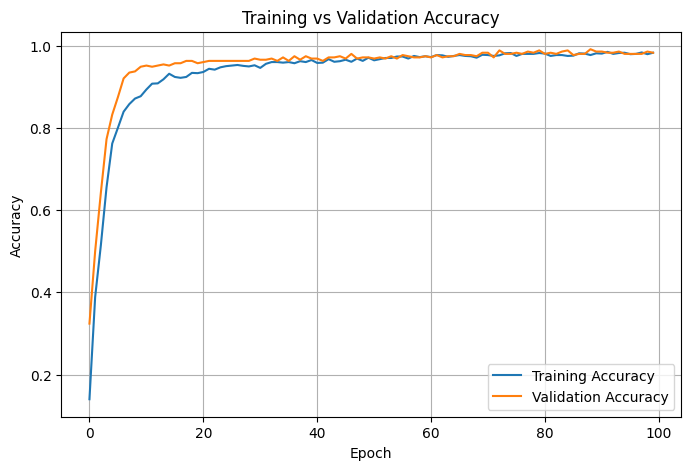

In [ ]:
# Plot accuracy across training epochs
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Training accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")

# Validation accuracy
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

# Add plot labels and formatting
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

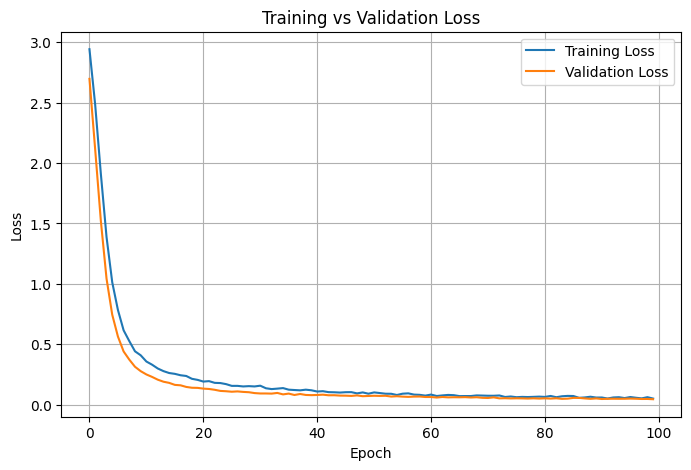

In [ ]:
# Plot the loss across training epochs
plt.figure(figsize=(8, 5))

# Training loss
plt.plot(history.history["loss"], label="Training Loss")

# Validation loss
plt.plot(history.history["val_loss"], label="Validation Loss")

# Add plot labels and formatting
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

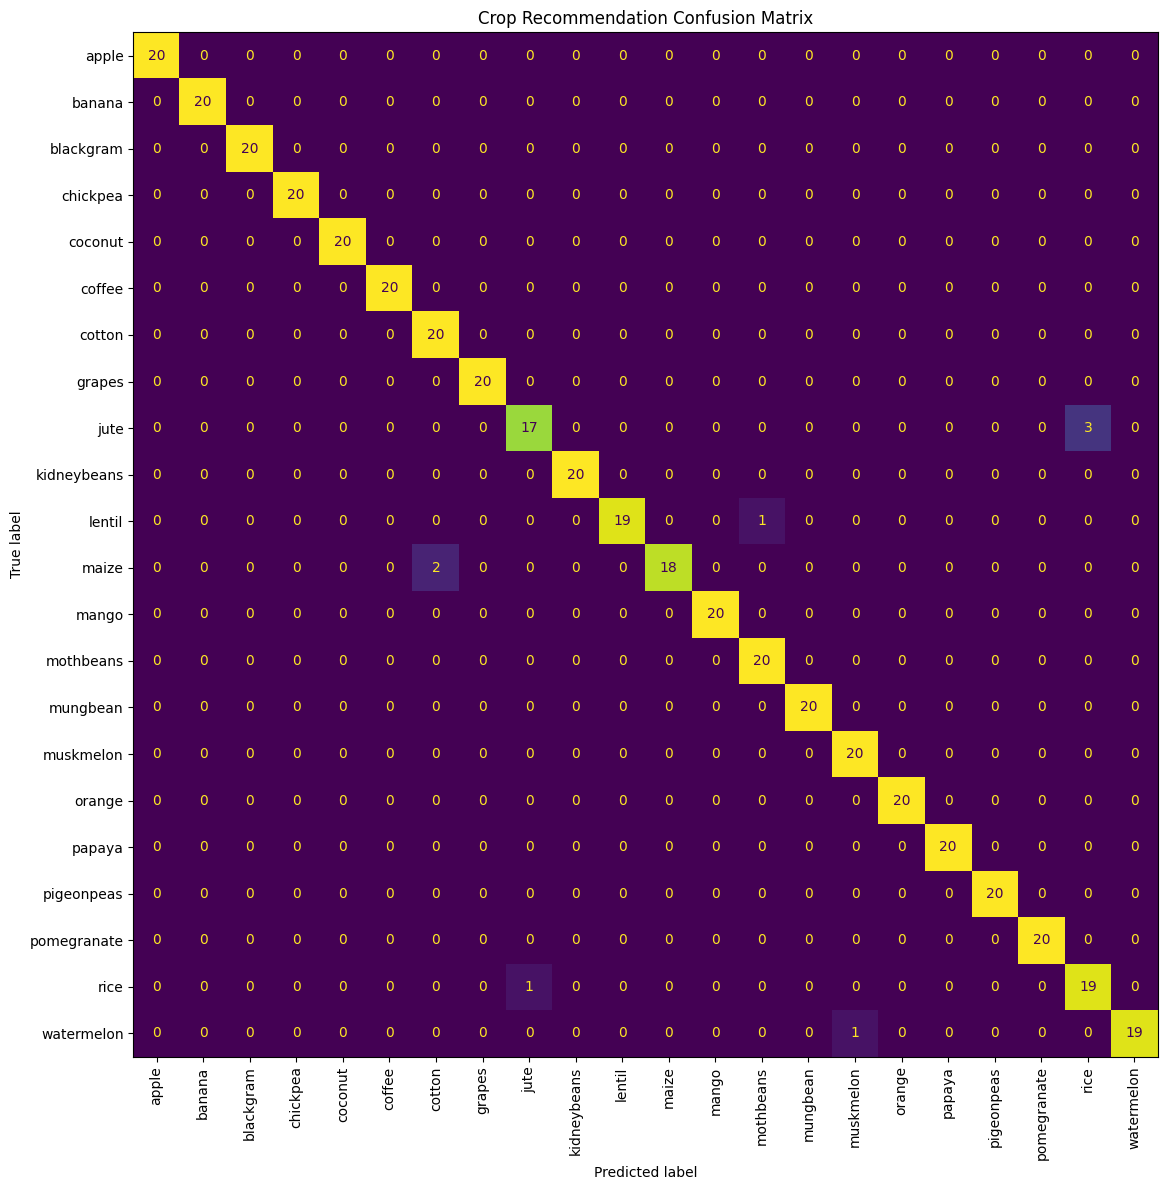

In [ ]:
# Import the confusion matrix function
from sklearn.metrics import ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_))
)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title("Crop Recommendation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Create a sample containing the seven input features
# Replace these example values with actual measurements
new_data = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.88,
    "humidity": 82.00,
    "ph": 6.50,
    "rainfall": 202.94
}])

# Ensure the feature order matches the training data
new_data = new_data[X.columns]

# Apply the previously fitted scaler
new_data_scaled = scaler.transform(new_data)

# Predict probabilities for all crop classes
probabilities = model.predict(new_data_scaled, verbose=0)[0]

# Find the crop class with the highest probability
best_index = np.argmax(probabilities)

# Convert the predicted integer back into the crop name
recommended_crop = le.inverse_transform([best_index])[0]

# Display the recommendation
print("Recommended crop:", recommended_crop)
print(
    "Predicted probability:",
    round(probabilities[best_index] * 100, 2),
    "%"
)

Recommended crop: rice
Predicted probability: 92.56 %


In [ ]:
# Find the indices of the three highest predicted probabilities
top_indices = np.argsort(probabilities)[-3:][::-1]

# Print the top three predicted crops
print("Top 3 crop recommendations:")

for index in top_indices:
    # Convert class index into crop name
    crop_name = le.inverse_transform([index])[0]

    # Convert probability into percentage
    confidence = probabilities[index] * 100

    print(f"{crop_name}: {confidence:.2f}%")

Top 3 crop recommendations:
rice: 92.56%
jute: 7.44%
cotton: 0.00%
